In [1]:
# Figure 3: Analysis of dataset types by region globally
# Nathan Erickson

In [1]:
# Import modules
import os
import string
import math
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.colors import Normalize,LogNorm

In [2]:
# Set directory structure
base_dir = '' # Fill your directory here
img_dir = os.path.join(base_dir,'FiguresForPaper')

In [ ]:
data_type = ['Observations','Reanalysis','Forecast Model'] * 3
data_region = ['Northern Hemisphere'] * 3 + ['Southern Hemisphere'] * 3 + ['Global'] * 3

# Total # datasets for each hemisphere/by type
nh_total = 705
sh_total = 68
global_total = 299

nh_obs = 477
nh_re = 216
nh_model = 200

sh_obs = 46
sh_re = 23
sh_model = 21 

global_obs = 136
global_re = 93
global_model = 151

nh_obs_freq = (nh_obs / nh_total) * 100
nh_re_freq = (nh_re / nh_total) * 100
nh_model_freq = (nh_model / nh_total) * 100

sh_obs_freq = (sh_obs / sh_total) * 100
sh_re_freq = (sh_re / sh_total) * 100
sh_model_freq = (sh_model / sh_total) * 100

global_obs_freq = (global_obs / global_total) * 100
global_re_freq = (global_re / global_total) * 100
global_model_freq = (global_model / global_total) * 100

data_counts = [nh_obs_freq,nh_re_freq,nh_model_freq,
               sh_obs_freq,sh_re_freq,sh_model_freq,
              global_obs_freq,global_re_freq,global_model_freq] # Not really counts, percentage

df_type = pd.DataFrame(data=[data_type,data_region,data_counts],index=['Type','Region','Frequency (%)']).T
df_type

# Pie plot setup
region_breakdowns = np.array([[316,85,120,101,49],
                     [25,9,12,7,2],
                     [89,57,104,13,14]])
label_breakdowns = ['NH - Obs.','NH - Reanalysis','NH - Forecast Model', 'NH - Obs. + Reanalysis', 'NH - Obs. + Forecast Model',
                    'SH - Obs.','SH - Reanalysis','SH - Forecast Model', 'SH - Obs. + Reanalysis', 'SH - Obs. + Forecast Model',
                    'Global - Obs.','Global - Reanalysis','Global - Forecsat Model', 'Global - Obs. + Reanalysis', 'Global - Obs. + Forecast Model']

regions = [f'Northern Hemisphere\n(n=671)',
           f'Southern Hemisphere\n(n=55)',
           f'Global\n(n=277)']

C:\Users\eric0051\AppData\Local\Temp\ipykernel_12176\4213631179.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  type_bar.set_xticklabels([f'N.H.\n(n=705)',f'S.H.\n(n=68)',f'Global\n(n=299)'],size=14)


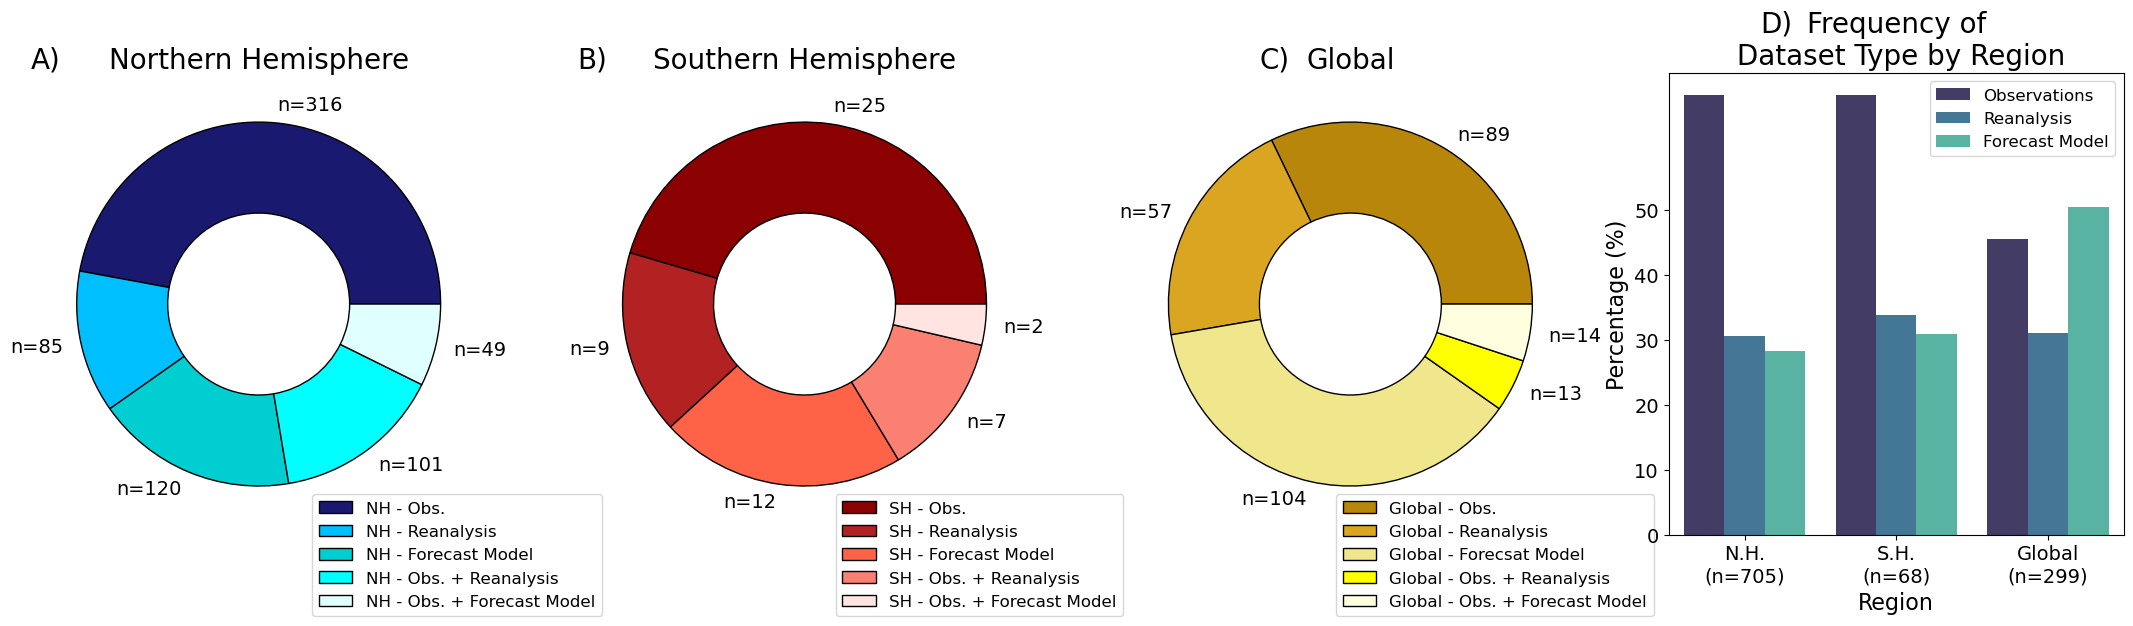

In [9]:
# Establish the figure object
fig_type,ax_type = plt.subplots(1,4,figsize=(27,6))

ax_pie_nh = ax_type[0]
ax_pie_sh = ax_type[1]
ax_pie_global = ax_type[2]
ax_bar = ax_type[3]

# Barplot
type_bar = sns.barplot(data=df_type,x='Region',y='Frequency (%)',hue='Type',palette='mako',orient='vertical',ax=ax_bar)
type_bar.set_ylabel('Percentage (%)',fontsize=16)
type_bar.set_xlabel('Region',fontsize=16)
type_bar.set_xticklabels([f'N.H. (n={nh_total})',f'S.H. (n={sh_total})',f'Global (n={global_total})'])

type_bar.set_yticks([0,10,20,30,40,50])
type_bar.set_yticklabels([0,10,20,30,40,50],size=14)

# Pie plot
# Colors
nh_color_sequence = ['midnightblue','deepskyblue','darkturquoise','cyan','lightcyan']
sh_color_sequence = ['darkred','firebrick','tomato','salmon','mistyrose']
global_color_sequence = ['darkgoldenrod','goldenrod','khaki','yellow','lightyellow']

mpl.color_sequences.register('pie_nh',nh_color_sequence)
mpl.color_sequences.register('pie_sh',sh_color_sequence)
mpl.color_sequences.register('pie_global',global_color_sequence)

nh_colors = plt.color_sequences['pie_nh']
sh_colors = plt.color_sequences['pie_sh']
global_colors = plt.color_sequences['pie_global']

nh_labels = [f'n={region_breakdowns.flatten()[i]}' for i in range(5)]
sh_labels = [f'n={region_breakdowns.flatten()[i]}' for i in range(5,10)]
global_labels = [f'n={region_breakdowns.flatten()[i]}' for i in range(10,15)]

nh_wedges, _ = ax_pie_nh.pie(region_breakdowns.flatten()[:5],labels=nh_labels,colors=nh_colors,
                             wedgeprops=dict(width=0.5, edgecolor='k'),textprops={'fontsize':14})
sh_wedges, _ = ax_pie_sh.pie(region_breakdowns.flatten()[5:10],labels=sh_labels,colors=sh_colors,
                             wedgeprops=dict(width=0.5, edgecolor='k'),textprops={'fontsize':14})
global_wedges, _ = ax_pie_global.pie(region_breakdowns.flatten()[10:],labels=global_labels,colors=global_colors,
                                     wedgeprops=dict(width=0.5, edgecolor='k'),textprops={'fontsize':14})

# Set titles
ax_pie_nh.set_title('Northern Hemisphere',fontsize=20)
ax_pie_sh.set_title('Southern Hemisphere',fontsize=20)
ax_pie_global.set_title('Global',fontsize=20)
ax_bar.set_title('Frequency of\n Dataset Type by Region',fontsize=20)

# Set legends
ax_pie_nh.legend(nh_wedges,label_breakdowns[:5],bbox_to_anchor=[0.6,0.1],fontsize='large')
ax_pie_sh.legend(sh_wedges,label_breakdowns[5:10],bbox_to_anchor=[0.55,0.1],fontsize='large')
ax_pie_global.legend(global_wedges,label_breakdowns[10:],bbox_to_anchor=[0.45,0.1],fontsize='large')
ax_bar.legend(fontsize='large')

for idx,axis in enumerate(ax_type):
    if idx < 2:
        axis.text(0,1.02,f'{string.ascii_uppercase[idx]})',fontsize=20,transform=axis.transAxes)
    elif idx < 3:
        axis.text(0.3,1.02,f'{string.ascii_uppercase[idx]})',fontsize=20,transform=axis.transAxes)
    else:
        axis.text(0.2,1.09,f'{string.ascii_uppercase[idx]})',fontsize=20,transform=axis.transAxes)

# Set color sequences properly

In [10]:
os.chdir(img_dir)
fig_type.savefig('Fig3.jpg',bbox_inches='tight',dpi=300)
os.getcwd()

'C:\\Users\\eric0051\\OneDrive - University of Oklahoma\\Documents\\PhD\\Research\\BAMS - Global AI Paper\\FiguresForPaper'